# Fed decision markets: Kalshi event contracts vs fed funds futures

**Objective:** part of my Graduating Project ("Two Markets for the Same State Price"). A Fed decision is an **event**, so here the event contract is the native instrument and the derivative (fed funds futures) is the indirect one, the opposite of a note written on a price level. We look at two things:

1. **Calibration:** in the FOMC meetings already resolved, how good were the Kalshi probabilities 1, 7 and 30 days before the decision? (Brier score, against simple benchmarks)
2. **Today:** do Kalshi and the fed funds futures (with the CME FedWatch method) give the same probabilities for the next meetings?

**Data:** Kalshi public API (series KXFEDDECISION, live and historical endpoints), fed funds futures from Yahoo Finance (CBOT ZQ contracts), effective fed funds rate from FRED (DFF).

Libraries of the project: `pandas`, `numpy`, `matplotlib`, `seaborn`, `requests` and `yfinance`.

## Part 1. Libraries

In [1]:
import json
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import yfinance as yf

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)
K = "https://api.elections.kalshi.com/trade-api/v2"

def get(url, params=None):
    for i in range(6):
        r = requests.get(url, params=params, timeout=60)
        if r.status_code == 429:
            time.sleep(2 + i)
            continue
        r.raise_for_status()
        return r.json()

## Part 2. FOMC events and markets on Kalshi

Each event (one meeting) has 5 markets: cut more than 25 bp, cut 25 bp, maintain, hike 25 bp, hike more than 25 bp. Old markets are in the historical endpoints of the API.

In [2]:
cambio = {"C26": -0.50, "C25": -0.25, "H0": 0.0, "H25": 0.25, "H26": 0.50}
ruta = "data/kalshi_fed_markets.csv"
if not os.path.exists(ruta):
    eventos = []
    for estado in ["settled", "open"]:
        cur = None
        while True:
            p = {"series_ticker": "KXFEDDECISION", "status": estado, "limit": 200}
            if cur:
                p["cursor"] = cur
            d = get(K + "/events", p)
            eventos += d["events"]
            cur = d.get("cursor")
            if not cur:
                break
    filas = []
    for e in eventos:
        info = get(K + "/events/" + e["event_ticker"])
        mercados = info.get("markets") or []
        if not mercados:
            mercados = get(K + "/historical/markets", {"event_ticker": e["event_ticker"], "limit": 50})["markets"]
        for m in mercados:
            filas.append({"event": e["event_ticker"], "meeting": info["event"].get("strike_date"), "ticker": m["ticker"],
                          "outcome": m["ticker"].split("-")[-1], "result": m.get("result"), "status": m.get("status"),
                          "yes_bid": m.get("yes_bid_dollars"), "yes_ask": m.get("yes_ask_dollars"), "close_time": m.get("close_time")})
    pd.DataFrame(filas).to_csv(ruta, index=False)
mk = pd.read_csv(ruta)
mk["meeting"] = pd.to_datetime(mk["meeting"], utc=True)
mk = mk[mk["outcome"].isin(cambio)]
print("Meetings:", mk["event"].nunique(), "| from", mk["meeting"].min().date(), "to", mk["meeting"].max().date())

Meetings: 39 | from 2023-05-03 to 2028-01-26


## Part 3. Daily prices before each resolved meeting

For each market we download the daily candlesticks of the 45 days before the meeting and take the mid price between the best bid and ask.

In [3]:
ruta_c = "data/kalshi_fed_daily.csv"
if not os.path.exists(ruta_c):
    filas = []
    cutoff = pd.Timestamp(get(K + "/historical/cutoff")["market_settled_ts"])
    resueltos = mk[mk["result"].isin(["yes", "no"])]
    for _, m in resueltos.iterrows():
        fin = int(pd.Timestamp(m["close_time"]).timestamp())
        params = {"start_ts": fin - 45 * 86400, "end_ts": fin, "period_interval": 1440}
        if pd.Timestamp(m["close_time"]) < cutoff:
            d = get(f"{K}/historical/markets/{m['ticker']}/candlesticks", params)
        else:
            d = get(f"{K}/series/KXFEDDECISION/markets/{m['ticker']}/candlesticks", params)
        for c in d.get("candlesticks", []):
            v = lambda x, k: (x or {}).get(k + "_dollars", (x or {}).get(k))
            filas.append({"ticker": m["ticker"], "ts": c["end_period_ts"], "bid": v(c.get("yes_bid"), "close"), "ask": v(c.get("yes_ask"), "close")})
        time.sleep(0.05)
    pd.DataFrame(filas).to_csv(ruta_c, index=False)
dia = pd.read_csv(ruta_c)
dia["mid"] = (pd.to_numeric(dia["bid"]) + pd.to_numeric(dia["ask"])) / 2
dia = dia.merge(mk[["ticker", "event", "outcome", "result", "meeting"]], on="ticker")
dia["days_before"] = ((dia["meeting"] - pd.to_datetime(dia["ts"], unit="s", utc=True)).dt.total_seconds() / 86400).round()
print("Daily prices:", len(dia), "| meetings with prices:", dia["event"].nunique())

Daily prices: 4525 | meetings with prices: 28


## Part 4. What happened in each meeting

In [4]:
resultado = mk[mk["result"] == "yes"][["event", "meeting", "outcome"]].sort_values("meeting")
resultado["change"] = resultado["outcome"].map(cambio)
resultado.tail(15)

,event,meeting,outcome,change
73,KXFEDDECISION-24DEC,2024-12-18 19:00:00+00:00,C25,-0.25
67,KXFEDDECISION-25JAN,2025-01-29 19:00:00+00:00,H0,0.00
62,KXFEDDECISION-25MAR,2025-03-19 18:00:00+00:00,H0,0.00
57,KXFEDDECISION-25MAY,2025-05-07 18:00:00+00:00,H0,0.00
52,KXFEDDECISION-25JUN,2025-06-18 18:00:00+00:00,H0,0.00
47,KXFEDDECISION-25JUL,2025-07-30 18:00:00+00:00,H0,0.00
44,KXFEDDECISION-25SEP,2025-09-17 18:00:00+00:00,C25,-0.25
39,KXFEDDECISION-25OCT,2025-10-29 18:00:00+00:00,C25,-0.25
33,KXFEDDECISION-25DEC,2025-12-10 19:00:00+00:00,C25,-0.25
27,KXFEDDECISION-26JAN,2026-01-28 19:00:00+00:00,H0,0.00


## Part 5. Calibration and Brier score

At 1, 7 and 30 days before each meeting we take the probability of the 5 outcomes (normalised so they sum 1) and calculate the multi-outcome Brier score: sum of (probability - result)^2. Lower is better. Two benchmarks:
- **"no change"**: probability 1 that the Fed maintains the rate
- **"repeat"**: probability 1 that the Fed does the same as in the previous meeting

In [5]:
filas = []
for h in [1, 7, 30]:
    sub = dia[(dia["days_before"] >= h) & (dia["days_before"] <= h + 2)]
    sub = sub.sort_values("days_before").groupby(["event", "outcome"]).first().reset_index()
    for ev, g in sub.groupby("event"):
        p = g.set_index("outcome")["mid"].reindex(list(cambio)).fillna(0)
        if p.sum() <= 0:
            continue
        p = p / p.sum()
        real = g.set_index("outcome")["result"].reindex(list(cambio)).eq("yes").astype(float)
        filas.append({"event": ev, "horizon": h, "brier": ((p - real) ** 2).sum(), "p_realised": float(p[real == 1].sum())})
cal = pd.DataFrame(filas)

res = resultado.set_index("event")
res["prev_outcome"] = res["outcome"].shift(1)
bench = []
for ev, r in res.iterrows():
    real = pd.Series([1.0 if o == r["outcome"] else 0.0 for o in cambio], index=list(cambio))
    no_cambio = pd.Series([1.0 if o == "H0" else 0.0 for o in cambio], index=list(cambio))
    rep = pd.Series([1.0 if o == r["prev_outcome"] else 0.0 for o in cambio], index=list(cambio)) if isinstance(r["prev_outcome"], str) else no_cambio
    bench.append({"event": ev, "brier_no_change": ((no_cambio - real) ** 2).sum(), "brier_repeat": ((rep - real) ** 2).sum()})
bench = pd.DataFrame(bench)
comp = cal.pivot(index="event", columns="horizon", values="brier").add_prefix("kalshi_").merge(bench, on="event")
print("Meetings compared:", len(comp))
comp.drop(columns="event").mean().round(3)

Meetings compared: 28


kalshi_1           0.022
kalshi_7           0.090
kalshi_30          0.144
brier_no_change    0.643
brier_repeat       0.714
dtype: float64

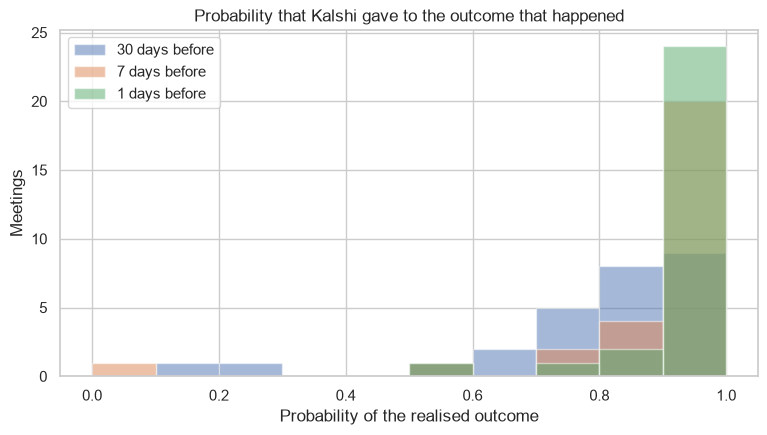

,count,mean,std,min,25%,50%,75%,max
horizon,,,,,,,,
1,28.0,0.941,0.093,0.548,0.951,0.973,0.980,0.995
7,28.0,0.888,0.188,0.069,0.889,0.956,0.980,0.990
30,27.0,0.796,0.198,0.147,0.749,0.844,0.931,0.980


In [6]:
plt.figure(figsize=(9, 4.5))
for h in [30, 7, 1]:
    x = cal[cal["horizon"] == h]
    plt.hist(x["p_realised"], bins=10, range=(0, 1), alpha=0.5, label=f"{h} days before")
plt.title("Probability that Kalshi gave to the outcome that happened")
plt.xlabel("Probability of the realised outcome")
plt.ylabel("Meetings")
plt.legend()
plt.savefig("figures/probability_realised.png", bbox_inches="tight")
plt.show()
cal.groupby("horizon")["p_realised"].describe().round(3)

## Part 6. The surprises

The meetings where the outcome had less than 50% of probability 7 days before:

In [7]:
sorpresas = cal[(cal["horizon"] == 7) & (cal["p_realised"] < 0.5)].merge(resultado[["event", "outcome"]], on="event")
sorpresas.sort_values("p_realised").round(3)

,event,horizon,brier,p_realised,outcome
0,FEDDECISION-24SEP,7,1.708,0.069,C26


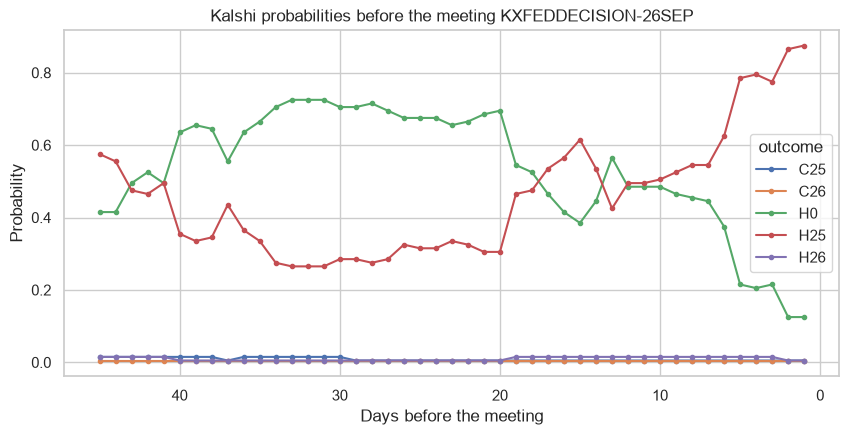

In [8]:
ultimo = resultado["event"].iloc[-1]
g = dia[dia["event"] == ultimo].pivot_table(index="days_before", columns="outcome", values="mid").sort_index(ascending=False)
g.plot(figsize=(10, 4.5), marker=".")
plt.gca().invert_xaxis()
plt.title(f"Kalshi probabilities before the meeting {ultimo}")
plt.xlabel("Days before the meeting")
plt.ylabel("Probability")
plt.savefig("figures/last_meeting.png", bbox_inches="tight")
plt.show()

## Part 7. Today: Kalshi vs fed funds futures (FedWatch method)

A fed funds future pays 100 minus the average effective rate of its month. If the meeting is on day d of a month of N days:

average rate of the month = (d / N) x rate before + (1 - d / N) x rate after

Like CME FedWatch, when the month after the meeting has no meeting, its contract gives directly the rate after the meeting (this is more stable). When the next month also has a meeting, we solve the formula for the rate after. Each meeting starts from the rate after the previous one.

In [9]:
dff = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DFF", index_col=0, parse_dates=True, na_values=".").iloc[:, 0].dropna()
tasa = dff.iloc[-1]
print("Effective fed funds today:", tasa, "on", dff.index[-1].date())

abiertas = mk[mk["status"].isin(["active", "open", "initialized"])].copy()
abiertas["mid"] = (pd.to_numeric(abiertas["yes_bid"]) + pd.to_numeric(abiertas["yes_ask"])) / 2
reuniones = abiertas.groupby("event")["meeting"].first().sort_values()
reuniones = reuniones[reuniones <= reuniones.min() + pd.Timedelta(days=330)]
meses_con_reunion = {(m.tz_convert("America/New_York").year, m.tz_convert("America/New_York").month) for m in reuniones}

codigos = {1: "F", 2: "G", 3: "H", 4: "J", 5: "K", 6: "M", 7: "N", 8: "Q", 9: "U", 10: "V", 11: "X", 12: "Z"}
def futuro(anio, mes):
    h = yf.Ticker(f"ZQ{codigos[mes]}{str(anio)[2:]}.CBT").history(period="5d")
    return None if h.empty else 100 - h["Close"].iloc[-1]

filas = []
antes = tasa
for ev, fecha in reuniones.items():
    f = fecha.tz_convert("America/New_York")
    siguiente = (f + pd.offsets.MonthBegin(1))
    if (siguiente.year, siguiente.month) not in meses_con_reunion and futuro(siguiente.year, siguiente.month) is not None:
        despues = futuro(siguiente.year, siguiente.month)
        metodo = "next month"
    else:
        promedio = futuro(f.year, f.month)
        if promedio is None:
            continue
        N = pd.Period(f.strftime("%Y-%m")).days_in_month
        despues = (promedio - f.day / N * antes) / (1 - f.day / N)
        metodo = "same month"
    g = abiertas[abiertas["event"] == ev].set_index("outcome")["mid"].reindex(list(cambio)).fillna(0)
    g = g / g.sum()
    filas.append({"meeting": f.date(), "method": metodo, "futures_expected_change_bp": (despues - antes) * 100,
                  "kalshi_expected_change_bp": float((g * pd.Series(cambio)).sum()) * 100,
                  "kalshi_p_hike": float(g[["H25", "H26"]].sum()), "kalshi_p_hold": float(g["H0"]), "kalshi_p_cut": float(g[["C25", "C26"]].sum())})
    antes = despues
hoy = pd.DataFrame(filas)
hoy["cumulative_futures_bp"] = hoy["futures_expected_change_bp"].cumsum()
hoy["cumulative_kalshi_bp"] = hoy["kalshi_expected_change_bp"].cumsum()
hoy.round(2)

Effective fed funds today: 3.88 on 2026-10-21


,meeting,method,futures_expected_change_bp,kalshi_expected_change_bp,kalshi_p_hike,kalshi_p_hold,kalshi_p_cut,cumulative_futures_bp,cumulative_kalshi_bp
0,2026-10-28,next month,2.00,1.24,0.06,0.93,0.01,2.00,1.24
1,2026-12-09,same month,20.43,18.75,0.73,0.25,0.02,22.43,19.99
2,2027-01-27,next month,8.07,7.23,0.31,0.66,0.03,30.50,27.22
3,2027-03-17,same month,13.29,11.14,0.57,0.30,0.13,43.79,38.36
4,2027-04-28,next month,8.21,4.70,0.31,0.59,0.10,52.00,43.06
5,2027-06-09,same month,7.86,8.46,0.36,0.61,0.03,59.86,51.52
6,2027-07-28,next month,3.14,3.84,0.21,0.74,0.05,63.00,55.36
7,2027-09-15,next month,1.00,2.34,0.19,0.71,0.10,64.00,57.70


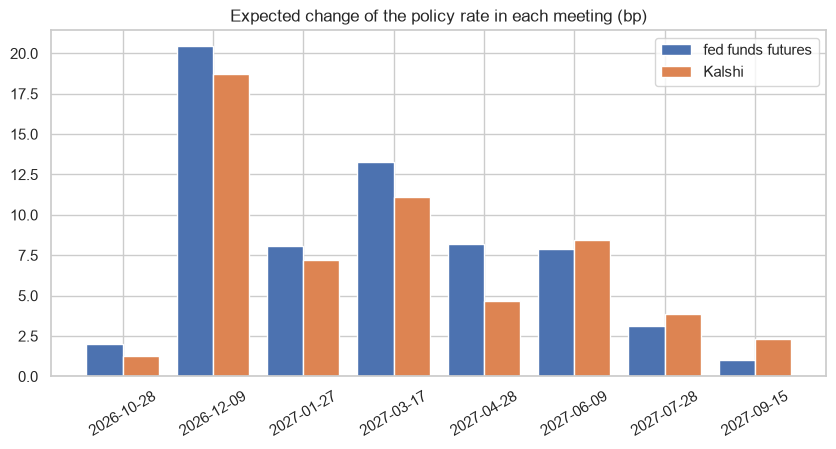

Mean absolute difference (bp): 1.4
Cumulative expected change until 2027-09-15 | futures: 64.0 bp | Kalshi: 57.7 bp


In [10]:
x = np.arange(len(hoy))
plt.figure(figsize=(10, 4.5))
plt.bar(x - 0.2, hoy["futures_expected_change_bp"], 0.4, label="fed funds futures")
plt.bar(x + 0.2, hoy["kalshi_expected_change_bp"], 0.4, label="Kalshi")
plt.xticks(x, hoy["meeting"].astype(str), rotation=30)
plt.axhline(0, color="black", lw=0.7)
plt.title("Expected change of the policy rate in each meeting (bp)")
plt.legend()
plt.savefig("figures/kalshi_vs_futures.png", bbox_inches="tight")
plt.show()
print("Mean absolute difference (bp):", round((hoy["futures_expected_change_bp"] - hoy["kalshi_expected_change_bp"]).abs().mean(), 1))
print("Cumulative expected change until", hoy["meeting"].iloc[-1], "| futures:", round(hoy["cumulative_futures_bp"].iloc[-1], 1), "bp | Kalshi:", round(hoy["cumulative_kalshi_bp"].iloc[-1], 1), "bp")

## Conclusions

- Kalshi Fed markets are well calibrated close to the decision. The Brier score (5 outcomes) is 0.022 one day before, 0.090 seven days before and 0.144 thirty days before, against 0.64 for "the Fed does not move" and 0.71 for "the Fed repeats the last decision". The median probability of the outcome that happened is 97% one day before.
- The big surprise in the sample is the 50 bp cut of September 2024: one week before, Kalshi gave it only 7%, and it moved to more than 50% only in the last days. The hike of September 2026 was more anticipated: 54% one week before and 87% the day before.
- Today the two markets agree very well: the expected change of the rate in each meeting differs on average by 1.4 bp, and until September 2027 the futures price 64 bp of hikes against 58 bp in Kalshi.
- For my Graduating Project this is the case where the event contract is the native hedge: for a note that pays if the Fed hikes, the Kalshi contract pays exactly on the event, while the futures only give the expected rate and leave a basis between the average of the month and the decision.